<font face="Times New Roman" size=5>
<div dir="rtl" align="center">

<br>
<font size=4 align=center>
Sharif University of Technology - Department of Electrical Engineering
</font>
<br>
<font color="#008080" size=6>
Introduction to Machine Learning
</font>

<hr/>
<font color="#80a080" size=5>
Computer Homework 4: MLP, CNN, and Kernel Methods
<br>
</font>
<font size=5>
Instructor: Dr. S. Amini
<br>
</font>
<font size=4>
Spring 2026
<br>
</font>
<hr>
</div></font>

<div dir="rtl">

Personal identification details have been omitted from this public portfolio copy.

</div>

In [1]:
# Common imports
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import ParameterGrid

# TODO: set this to the last 5 digits of your student id
STUDENT_SEED = 11147
np.random.seed(STUDENT_SEED)
random.seed(STUDENT_SEED)

DATA_DIR = "data"
plt.rcParams["figure.figsize"] = (6, 4)

# Problem 1: Multi-Layer Perceptron on a Real Tabular Dataset — 30 pts

<div dir="rtl">

در این مسئله از دیتاست استاندارد Wisconsin Breast Cancer استفاده می‌کنیم. هر نمونه شامل چند ویژگی عددی از تصویر سلول است و هدف، تشخیص malignant یا benign بودن نمونه است. در فایل‌های داده این تمرین، target=1 به معنی malignant/high-risk و target=0 به معنی benign است.

در این بخش قرار است مسیر زیر را طی کنید:

1. داده را بررسی و استانداردسازی کنید؛
2. یک مدل خطی پایه بسازید تا محدودیت مدل خطی را ببینید؛
3. یک MLP را از صفر با NumPy پیاده‌سازی کنید؛
4. درستی backpropagation را با gradient checking بررسی کنید؛
5. اثر activation، initialization و regularization را تحلیل کنید.

</div>

## 1.1 Loading, preprocessing, and exploratory analysis — 4 pts

<div dir="rtl">

کارهای لازم:

- فایل‌های train، validation و test را بخوانید.
- ابعاد داده، نام ویژگی‌ها و توزیع کلاس‌ها را گزارش کنید.
- ویژگی‌ها را با StandardScaler فقط بر اساس داده train استاندارد کنید.
- حداقل دو نمودار بسازید: یکی برای class balance و یکی برای رابطه دو ویژگی مهم با target.

سوال: آیا کلاس‌ها کاملا متوازن هستند؟ اگر نه، این موضوع چه اثری روی معیار accuracy می‌تواند داشته باشد؟

خیر، زیرا نزدیک به 63 درصد از داده ها مربوط به کیس bening می باشند و در صورت وجود عدم تعادل بین داده های در دسترس از کلاس های مختلف،accuracyمعیار مناسبی برای سنجش عملکرد مدل نمی تواند باشد زیرا حتی یک مدل ساده که feature ها را یاد نگرفته و فقط اکثریت را به عنوان خروجی انتخاب می کند هم در این کیس میتواند accuracy بالایی داشته باشد.

</div>

In [3]:
train_df = pd.read_csv(os.path.join(DATA_DIR, "breast_cancer_train.csv"))
val_df = pd.read_csv(os.path.join(DATA_DIR, "breast_cancer_val.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "breast_cancer_test.csv"))

# TODO: inspect train_df using head, describe, and class counts
display(train_df.head())
display(train_df.describe())
print(train_df["target"].value_counts())
print(train_df["target"].value_counts(normalize=True))

# TODO: split X/y and standardize features using only the training split

feature_cols = [c for c in train_df.columns if c != "target"]

X_train_raw, y_train = train_df[feature_cols].values, train_df["target"].values
X_val_raw, y_val = val_df[feature_cols].values, val_df["target"].values
X_test_raw, y_test = test_df[feature_cols].values, test_df["target"].values

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,14.780,23.94,97.40,668.3,0.11720,0.14790,0.12670,0.09029,0.1953,0.06654,...,33.39,114.60,925.1,0.16480,0.34160,0.3024,0.16140,0.3321,0.08911,1
1,9.667,18.49,61.49,289.1,0.08946,0.06258,0.02948,0.01514,0.2238,0.06413,...,25.62,70.88,385.2,0.12340,0.15420,0.1277,0.06560,0.3174,0.08524,0
2,14.640,16.85,94.21,666.0,0.08641,0.06698,0.05192,0.02791,0.1409,0.05355,...,25.44,106.00,831.0,0.11420,0.20700,0.2437,0.07828,0.2455,0.06596,0
3,19.550,23.21,128.90,1174.0,0.10100,0.13180,0.18560,0.10210,0.1989,0.05884,...,30.44,142.00,1313.0,0.12510,0.24140,0.3829,0.18250,0.2576,0.07602,1
4,12.270,29.97,77.42,465.4,0.07699,0.03398,0.00000,0.00000,0.1701,0.05960,...,38.05,85.08,558.9,0.09422,0.05213,0.0000,0.00000,0.2409,0.06743,0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000,...,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000
mean,14.107827,19.583636,91.724311,652.242522,0.095864,0.101609,0.086078,0.047949,0.181541,0.062561,...,26.061466,106.796100,873.151320,0.131616,0.246855,0.265442,0.113712,0.289965,0.083408,0.372434
std,3.490660,4.355908,23.960088,344.612598,0.014470,0.052701,0.079273,0.038237,0.027555,0.007251,...,6.161684,32.652081,546.229578,0.023554,0.154411,0.207072,0.065586,0.064468,0.018314,0.484164
min,7.691000,9.710000,47.980000,170.400000,0.062510,0.019380,0.000000,0.000000,0.106000,0.050240,...,12.020000,54.490000,223.600000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.600000,16.490000,74.650000,409.000000,0.084810,0.062190,0.028910,0.019690,0.163000,0.057230,...,21.740000,83.510000,507.200000,0.114300,0.141500,0.114500,0.064130,0.251000,0.070830,0.000000
50%,13.270000,19.070000,86.180000,545.200000,0.094950,0.089950,0.057860,0.033230,0.179700,0.061100,...,25.500000,97.580000,683.400000,0.129800,0.210100,0.222000,0.099750,0.280600,0.079870,0.000000
75%,16.030000,22.040000,105.100000,798.800000,0.104400,0.127300,0.122600,0.069870,0.195700,0.066150,...,30.380000,126.700000,1138.000000,0.146000,0.317100,0.378800,0.160900,0.316900,0.091660,1.000000
max,28.110000,39.280000,188.500000,2499.000000,0.163400,0.345400,0.426800,0.201200,0.290600,0.097440,...,49.540000,214.000000,3432.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


target
0    214
1    127
Name: count, dtype: int64
target
0    0.627566
1    0.372434
Name: proportion, dtype: float64


## 1.2 Linear baseline — 5 pts

<div dir="rtl">

یک Logistic Regression یا Perceptron آماده از sklearn آموزش دهید. سپس موارد زیر را گزارش کنید:

- accuracy روی train، validation و test؛
- confusion matrix روی test؛
- سه ویژگی با بزرگ‌ترین قدر مطلق وزن در مدل خطی.

سوال: مدل خطی از روی کدام ویژگی‌ها بیشتر تصمیم می‌گیرد؟ آیا این تصمیم‌گیری از نظر داده قابل توضیح است؟

با توجه به وزن‌های مدل خطی، سه ویژگی‌ای که بیشترین تأثیر را در تصمیم‌گیری مدل دارند عبارت‌اند از: **worst texture** (با ضریب مثبت ۱.۱۸)، **radius error** (با ضریب مثبت ۱.۱۵) و **worst symmetry** (با ضریب مثبت ۱.۰۷).

از نظر داده، این انتخاب قابل توضیح است:

- **worst texture**: نشان‌دهنده‌ی بیشترین میزان ناهمگنی (variation) در شدت پیکسل‌های هسته‌ی سلولی است. سلول‌های سرطانی معمولاً ساختار هسته‌ی نامنظم‌تر و بافت ناهمگن‌تری دارند، پس طبیعی است که هرچه این مقدار بیشتر باشد، احتمال malignant بودن (target=1) بالاتر برود . همسو با علامت مثبت ضریب.

- **radius error**: یعنی انحراف معیار (تغییرپذیری) شعاع سلول در طول نمونه‌برداری. تومورهای بدخیم معمولاً از نظر شکل و اندازه نامنظم‌تر و ناپایدارتر هستند، در نتیجه واریانس بالاتر در شعاع، نشانه‌ای از بدخیمی محسوب می‌شود.

- **worst symmetry**: بدترین (بیشترین) میزان عدم تقارن سلول. سلول‌های سالم (benign) معمولاً تقارن هندسی بیشتری دارند، در حالی که سلول‌های سرطانی به دلیل رشد غیرطبیعی، تقارن کمتری دارند؛ بنابراین مقدار بالای این ویژگی هم با احتمال بیشتر malignant بودن هم‌جهت است.

</div>

In [4]:
# TODO: train a linear baseline model
from sklearn.linear_model import LogisticRegression

linear_model = LogisticRegression(random_state=STUDENT_SEED, max_iter=1000)
linear_model.fit(X_train, y_train)

# TODO: report train/val/test accuracy
train_acc = accuracy_score(y_train, linear_model.predict(X_train))
val_acc = accuracy_score(y_val, linear_model.predict(X_val))
test_acc = accuracy_score(y_test, linear_model.predict(X_test))

print(f"Train accuracy:      {train_acc:.4f}")
print(f"Validation accuracy: {val_acc:.4f}")
print(f"Test accuracy:       {test_acc:.4f}")

# TODO: show confusion matrix and important coefficients
y_test_pred = linear_model.predict(X_test)
cm = confusion_matrix(y_test, y_test_pred)
print("\nConfusion matrix (test):")
print(cm)
print("\nClassification report (test):")

coefs = linear_model.coef_[0]
coef_df = pd.DataFrame({"feature": feature_cols, "coefficient": coefs})
coef_df["abs_coefficient"] = coef_df["coefficient"].abs()
top3 = coef_df.sort_values("abs_coefficient", ascending=False).head(3)
print("\nTop 3 features by |coefficient|:")
print(top3[["feature", "coefficient"]])


Train accuracy:      0.9912
Validation accuracy: 0.9737
Test accuracy:       0.9649

Confusion matrix (test):
[[72  0]
 [ 4 38]]

Classification report (test):

Top 3 features by |coefficient|:
           feature  coefficient
21   worst texture     1.183070
10    radius error     1.147540
28  worst symmetry     1.070901


## 1.3 Implementing an MLP from scratch with NumPy — 10 pts

<div dir="rtl">

در این قسمت نباید از PyTorch، TensorFlow یا sklearn.neural_network استفاده کنید. باید اجزای زیر را خودتان با NumPy پیاده‌سازی کنید:

- لایه Dense با forward و backward؛
- فعال‌سازهای ReLU، Tanh و Sigmoid؛
- تابع Binary Cross Entropy؛
- حلقه آموزش mini-batch gradient descent یا Adam ساده؛
- تابع predict.

راهنمایی: خروجی نهایی شبکه را می‌توانید یک عدد بین صفر و یک در نظر بگیرید و برای آن از sigmoid استفاده کنید.

</div>

In [5]:
class Dense:
    def __init__(self, in_features, out_features, init="xavier", seed=0):
        # TODO: initialize W and b
        np.random.seed(seed)

        if init == "xavier":
            limit = np.sqrt(6.0 / (in_features + out_features))
            self.W = np.random.uniform(-limit, limit, (in_features, out_features))
        elif init == "he":
            std = np.sqrt(2.0 / in_features)
            self.W = np.random.randn(in_features, out_features) * std
        elif init == "random":
            self.W = np.random.randn(in_features, out_features) * 0.01
        else:
            raise ValueError(f"Unknown init: {init}")

        self.b = np.zeros((1, out_features))
        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)
        self.x = None

    def forward(self, x):
        # TODO
        self.x = x
        return x @ self.W + self.b

    def backward(self, grad_output):
        # TODO: compute dW, db, and grad_input

        self.dW = self.x.T @ grad_output
        self.db = np.sum(grad_output, axis=0, keepdims=True)
        grad_input = grad_output @ self.W.T
        return grad_input

    def step(self, lr, weight_decay=0.0):
        # TODO: update parameters
        if weight_decay > 0.0:
            self.dW += weight_decay * self.W
            
        self.W -= lr * self.dW
        self.b -= lr * self.db

class ReLU:
    def forward(self, x):
        self.x = x
        return np.maximum(0, x)

    def backward(self, grad_output):
        return grad_output * (self.x > 0)
    

class Tanh:
    def forward(self, x):
        # TODO
        self.out = np.tanh(x)
        return self.out

    def backward(self, grad_output):
        # TODO
        return grad_output * (1 - self.out ** 2)

class Sigmoid:
    def forward(self, x):
        # TODO
        self.out = 1.0 / (1.0 + np.exp(-np.clip(x, -500, 500)))
        return self.out

    def backward(self, grad_output):
        # TODO
        return grad_output * self.out * (1 - self.out)

# TODO: implement BCE loss and its gradient
class BCELoss:
    def __init__(self, eps=1e-15):
        self.eps = eps
        
    def forward(self, y_pred, y_true):
        self.y_pred = np.clip(y_pred, self.eps, 1 - self.eps)
        self.y_true = y_true
        loss = -np.mean(y_true * np.log(self.y_pred) + (1 - y_true) * np.log(1 - self.y_pred))
        return loss
        
    def backward(self):
        N = self.y_true.shape[0]
        grad = (self.y_pred - self.y_true) / (self.y_pred * (1 - self.y_pred))
        return grad / N

# TODO: implement an MLP class using a list of layers
class MLP:
    def __init__(self, layers):
        self.layers = layers
        
    def forward(self, x):
        out = x
        for layer in self.layers:
            out = layer.forward(out)
        return out
        
    def backward(self, grad):
        for layer in reversed(self.layers):
            grad = layer.backward(grad)
            
    def step(self, lr, weight_decay=0.0):
        for layer in self.layers:
            if hasattr(layer, 'step'):  
                layer.step(lr, weight_decay)
            
    def predict(self, x, threshold=0.5):
        y_pred = self.forward(x)
        return (y_pred >= threshold).astype(int)

# TODO: implement a training loop
def train_mlp(model, X_train, y_train, X_val=None, y_val=None, epochs=100, batch_size=32, lr=0.01, weight_decay=0.0, verbose=False):
    criterion = BCELoss()
    n_samples = X_train.shape[0]
    history = {'train_loss': [], 'val_acc': []}

    for epoch in range(epochs):
        indices = np.random.permutation(n_samples)
        X_shuffled = X_train[indices]
        y_shuffled = y_train[indices]

        epoch_losses = []
        for i in range(0, n_samples, batch_size):
            X_batch = X_shuffled[i:i + batch_size]
            y_batch = y_shuffled[i:i + batch_size]

            y_pred = model.forward(X_batch)
            loss = criterion.forward(y_pred, y_batch)
            epoch_losses.append(loss)

            grad_loss = criterion.backward()
            model.backward(grad_loss)
            model.step(lr, weight_decay)

        avg_loss = np.mean(epoch_losses)
        history['train_loss'].append(avg_loss)

        if X_val is not None and y_val is not None:
            val_preds = model.predict(X_val)
            val_acc = accuracy_score(y_val, val_preds)
            history['val_acc'].append(val_acc)

        if verbose and ((epoch + 1) % 10 == 0 or epoch == 0):
            msg = f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f}"
            if X_val is not None:
                msg += f" | Val Acc: {history['val_acc'][-1]:.4f}"
            print(msg)

    return history

## 1.4 Gradient checking — 4 pts

<div dir="rtl">

برای 5 پارامتر تصادفی از شبکه، gradient تحلیلی حاصل از backpropagation را با gradient عددی finite difference مقایسه کنید.

برای هر پارامتر مقدار زیر را گزارش کنید:
</div>

<div dir="ltr">

$$
\frac{|g_{analytic}-g_{numeric}|}{|g_{analytic}|+|g_{numeric}|+10^{-12}}
$$

</div>

<div dir="rtl">
سوال: اگر اختلاف gradient بزرگ باشد، محتمل‌ترین خطاها در کدام بخش‌های کد هستند؟

</div>

<div dir="rtl">

توابع لایه‌های اکتیویشن: اشتباه در فرمول مشتق تحلیلی در متدهای backward (مثل Sigmoid یا Tanh).

کلاس Dense: اشتباه در Transpose کردن ماتریس‌ها هنگام محاسبه self.dW در متد backward، یا جمع نکردن صحیح گرادیان‌ها در راستای محور درست برای self.db.

تابع Loss: فراموش کردن تقسیم گرادیان بر N (تعداد نمونه‌های بچ) در متد backward کلاس BCELoss.
</div>

In [6]:
# TODO: implement gradient_check(model, X_batch, y_batch)

def gradient_check(model, X_batch, y_batch, num_checks=5, epsilon=1e-5):

    criterion = BCELoss()

    y_pred = model.forward(X_batch)
    loss = criterion.forward(y_pred, y_batch)
    grad_loss = criterion.backward()
    model.backward(grad_loss)

    params_info = []
    for layer_idx, layer in enumerate(model.layers):
        if hasattr(layer, 'W'):

            for i in range(layer.W.shape[0]):
                for j in range(layer.W.shape[1]):
                    params_info.append((layer, 'W', (i, j), layer.dW[i, j]))

            for i in range(layer.b.shape[0]):
                for j in range(layer.b.shape[1]):
                    params_info.append((layer, 'b', (i, j), layer.db[i, j]))

    np.random.seed(42)
    indices = np.random.choice(len(params_info), num_checks, replace=False)
    selected_params = [params_info[idx] for idx in indices]

    print(f"{'Layer':<10} | {'Param':<5} | {'Index':<10} | {'Rel Error'}")

    for layer, param_name, idx, g_analytic in selected_params:
        param_array = getattr(layer, param_name)
        original_value = param_array[idx]

        param_array[idx] = original_value + epsilon
        loss_plus = criterion.forward(model.forward(X_batch), y_batch)

        param_array[idx] = original_value - epsilon
        loss_minus = criterion.forward(model.forward(X_batch), y_batch)

        param_array[idx] = original_value

        g_numeric = (loss_plus - loss_minus) / (2 * epsilon)

        numerator = abs(g_analytic - g_numeric)
        denominator = abs(g_analytic) + abs(g_numeric) + 1e-12
        rel_error = numerator / denominator

        layer_name = layer.__class__.__name__
        print(f"{layer_name:<10} | {param_name:<5} | {str(idx):<10} | {rel_error:.4e}")



n_features = X_train.shape[1]

model = MLP([
    Dense(n_features, 16, init="xavier", seed=STUDENT_SEED),
    ReLU(),
    Dense(16, 1, init="xavier", seed=STUDENT_SEED + 1),
    Sigmoid(),
])


y_train_col = y_train.reshape(-1, 1).astype(float)

X_batch = X_train[:32]
y_batch = y_train_col[:32]

# TODO: report relative errors for 5 randomly selected parameters
gradient_check(model, X_batch, y_batch, num_checks=5)

Layer      | Param | Index      | Rel Error
Dense      | W     | (19, 0)    | 2.3803e-11
Dense      | W     | (0, 0)     | 1.1794e-10
Dense      | W     | (27, 7)    | 3.5500e-11
Dense      | W     | (9, 9)     | 4.5290e-10
Dense      | W     | (2, 0)     | 2.6498e-11


## 1.5 Activation, initialization, and regularization experiments — 7 pts

<div dir="rtl">

حداقل چهار تنظیم مختلف را مقایسه کنید. مثلا:

</div>

<div dir="ltr">

1. Sigmoid + small random initialization؛
2. Tanh + Xavier initialization؛
3. ReLU + He initialization؛
4. ReLU + He + L2 regularization.

</div>

<div dir="rtl">

برای هر تنظیم، نمودار train loss و validation accuracy را رسم کنید و جدول نهایی بسازید.

سوالات:

- کدام activation سریع‌تر آموزش دید؟ چرا؟

تابع فعال‌ساز ReLU سریع‌ترین همگرایی و آموزش را داشت. دلیل این امر، غلبه بر مشکل Vanishing Gradient Problem است که در توابع Sigmoid و Tanh بسیار رایج است. از آنجا که مشتق ReLU برای مقادیر مثبت همیشه برابر با یک است، سیگنال گرادیان در طول Backpropagation تضعیف نمی‌شود و وزن‌ها با سرعت و پایداری بیشتری آپدیت می‌شوند.

- آیا نشانه‌ای از overfitting دیدید؟

نشانه‌های Overfitting به ویژه در ساختار ReLU بدون Unregularized کاملاً مشهود بود. در این حالت، Training Loss به شدت کاهش یافته، در حالی که عملکرد مدل روی داده‌های Validation از یک نقطه به بعد متوقف شد و بهبود نیافت.

- regularization چه اثری روی فاصله train و validation داشت؟

استفاده از تنظیم‌گر  L2
 با جریمه کردن وزن‌های بزرگ و محدود کردن رشد پارامترهای شبکه، پیچیدگی مدل را کنترل کرد. این کار باعث شد فاصله (Gap) بین عملکرد داده‌های آموزش و اعتبارسنجی به شکل قابل توجهی کاهش یابد و مدل توانایی تعمیم‌پذیری (Generalization) بهتری روی داده‌های ندیده پیدا کند.

- آیا MLP نسبت به مدل خطی بهبود معنادار داشت؟

خیر، بهبود معنادار و چشمگیری مشاهده نشد. از آنجایی که ویژگی‌های مجموعه داده سرطان سینه (Breast Cancer) تا حد زیادی به صورت خطی تفکیک‌پذیر (Linearly Separable) هستند، مدل پایه خطی (Logistic Regression) عملکردی بسیار نزدیک و قابل مقایسه با شبکه عصبی چندلایه (MLP) ارائه داد. این موضوع نشان می‌دهد که برای این مجموعه داده خاص، استفاده از مدل‌های ساده‌تر کاملاً کفایت می‌کند.

</div>

Finished 1. Sigmoid + Random
Finished 2. Tanh + Xavier
Finished 3. ReLU + He
Finished 4. ReLU + He + L2


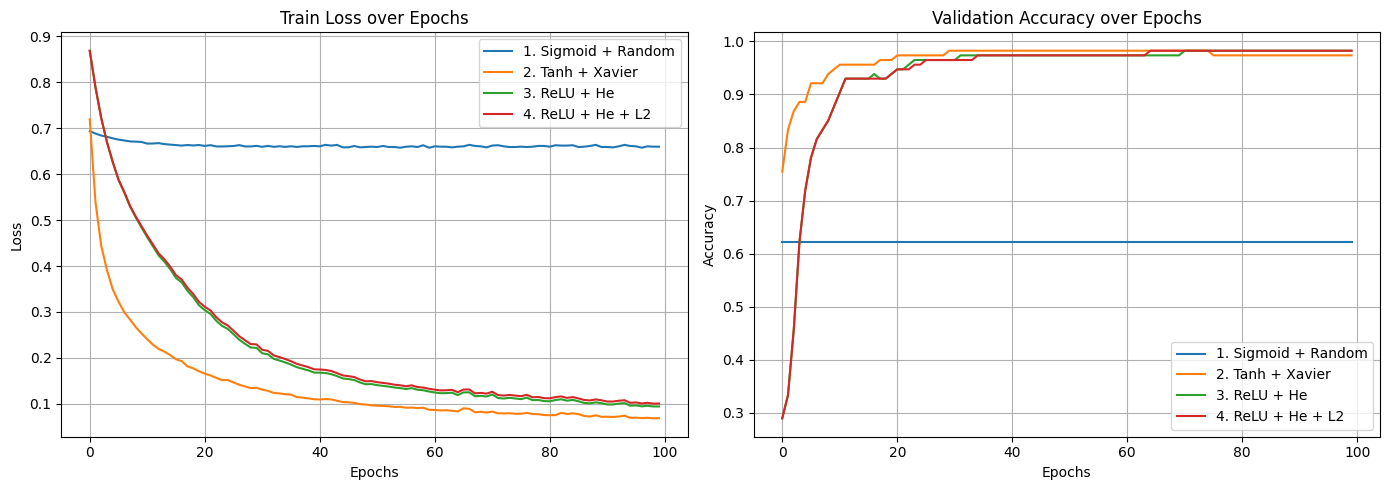

,Experiment,Final Train Loss,Final Val Accuracy
0,1. Sigmoid + Random,0.659689,0.622807
1,2. Tanh + Xavier,0.068861,0.973684
2,3. ReLU + He,0.094373,0.982456
3,4. ReLU + He + L2,0.100768,0.982456


In [7]:
# TODO: run at least four experiments
# TODO: plot training curves
# TODO: create a result table
# TODO: write your analysis in a markdown cell below

epochs = 100
learning_rate = 0.01
batch_size = 32

histories = {}
results = []
y_val_col = y_val.reshape(-1, 1).astype(float)

def run_experiment(name, model, weight_decay=0.0):
    history = train_mlp(
        model, X_train, y_train_col,
        X_val=X_val, y_val=y_val_col,
        epochs=epochs, lr=learning_rate, batch_size=batch_size,
        weight_decay=weight_decay
    )
    histories[name] = history

    final_train_loss = history['train_loss'][-1]
    final_val_acc = history['val_acc'][-1]
    results.append({
        'Experiment': name,
        'Final Train Loss': final_train_loss,
        'Final Val Accuracy': final_val_acc
    })
    print(f"Finished {name}")

in_features = X_train.shape[1]

# 1. Sigmoid + small random initialization
model_1 = MLP([
    Dense(in_features, 16, init="random", seed=42), Sigmoid(),
    Dense(16, 8, init="random", seed=42), Sigmoid(),
    Dense(8, 1, init="random", seed=42), Sigmoid()
])
run_experiment("1. Sigmoid + Random", model_1)

# 2. Tanh + Xavier initialization
model_2 = MLP([
    Dense(in_features, 16, init="xavier", seed=42), Tanh(),
    Dense(16, 8, init="xavier", seed=42), Tanh(),
    Dense(8, 1, init="xavier", seed=42), Sigmoid()
])
run_experiment("2. Tanh + Xavier", model_2)

# 3. ReLU + He initialization
model_3 = MLP([
    Dense(in_features, 16, init="he", seed=42), ReLU(),
    Dense(16, 8, init="he", seed=42), ReLU(),
    Dense(8, 1, init="he", seed=42), Sigmoid()
])
run_experiment("3. ReLU + He", model_3)

# 4. ReLU + He + L2 regularization
model_4 = MLP([
    Dense(in_features, 16, init="he", seed=42), ReLU(),
    Dense(16, 8, init="he", seed=42), ReLU(),
    Dense(8, 1, init="he", seed=42), Sigmoid()
])
run_experiment("4. ReLU + He + L2", model_4, weight_decay=0.01)


plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
for name, hist in histories.items():
    plt.plot(hist['train_loss'], label=name)
plt.title('Train Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
for name, hist in histories.items():
    plt.plot(hist['val_acc'], label=name)
plt.title('Validation Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

df_results = pd.DataFrame(results)
display(df_results)


# Problem 2: Convolutional Neural Networks on Handwritten Digits — 35 pts + 4 bonus

<div dir="rtl">

در این مسئله از دیتاست استاندارد Digits استفاده می‌کنیم. هر تصویر یک رقم دست‌نویس 8 در 8 است و هدف، دسته‌بندی رقم بین 0 تا 9 است. اندازه تصاویر کوچک است تا تمرکز تمرین روی مفهوم CNN و تحلیل مدل باشد، نه روی هزینه محاسباتی زیاد.

در این بخش قرار است:

1. کانولوشن را دستی پیاده‌سازی کنید؛
2. یک MLP روی تصویر flatten‌شده و یک CNN ساده آموزش دهید؛
3. یک CNN بهتر با محدودیت تعداد پارامتر طراحی کنید؛
4. خطاهای مدل را تحلیل کنید؛
5. برای امتیازی، پایداری مدل را روی داده‌های خراب‌شده بررسی کنید.

</div>

## 2.1 Manual convolution, padding, stride, and receptive field — 6 pts

<div dir="rtl">

فایل `manual_digit_8x8.csv` یک تصویر 8 در 8 از دیتاست digits است. ابتدا تصویر را نمایش دهید. سپس تابع conv2d را با NumPy پیاده‌سازی کنید.

کارهای لازم:

- سه فیلتر 3 در 3 طراحی یا استفاده کنید: edge horizontal، edge vertical و یک فیلتر دلخواه برای pattern انتخابی خودتان؛
- خروجی convolution را برای stride=1 و padding=0 نمایش دهید؛
- خروجی را برای same padding و برای stride=2 مقایسه کنید؛
- برای یک خانه مشخص از خروجی، receptive field متناظر در ورودی را مشخص کنید.

سوال: stride و padding چه اثری روی اندازه خروجی و اطلاعات مرزی تصویر دارند؟

اثر Padding: مقدار Padding مرزهای تصویر را با صفرهای مجازی پر می‌کند. این کار باعث می‌شود هسته کانولوشن بتواند مرکز خود را روی پیکسل‌های لبه‌ای تصویر قرار دهد. در نتیجه اطلاعات مرزی (Edge Information) حفظ می‌شوند و ابعاد تصویر پس از کانولوشن کاهش ناگهانی پیدا نمی‌کند (حالت Same Padding).

اثر Stride:
 گام حرکت یا Stride تعیین می‌کند که فیلتر در هر مرحله چند پیکسل جابجا شود. افزایش Stride باعث می‌شود ما از روی پیکسل‌ها بپریم (Downsampling)، در نتیجه اندازه خروجی به شدت کاهش می‌یابد.

</div>

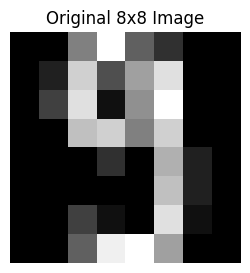

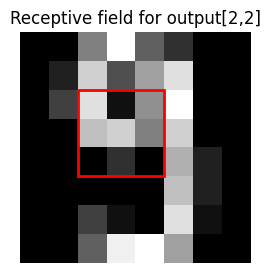

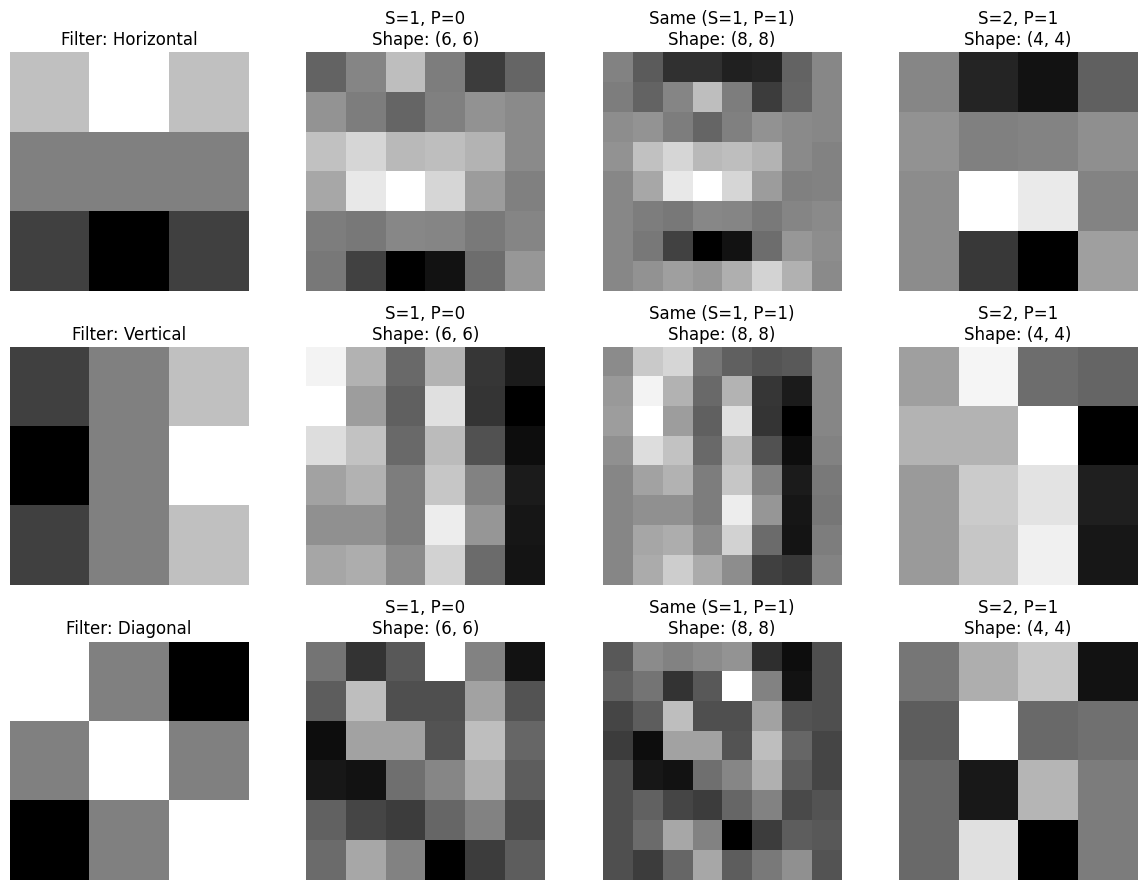

In [21]:
manual_img = pd.read_csv(os.path.join(DATA_DIR, "manual_digit_8x8.csv"), header=None).values.astype(float)

# TODO: visualize manual_img

manual_img = pd.read_csv(os.path.join(DATA_DIR, "manual_digit_8x8.csv"), header=None).values.astype(float)

plt.figure(figsize=(3, 3))
plt.imshow(manual_img, cmap='gray')
plt.title("Original 8x8 Image")
plt.axis('off')
plt.show()

# TODO: implement conv2d_numpy(image, kernel, padding=0, stride=1)

def conv2d_numpy(image, kernel, padding=0, stride=1):

    if padding > 0:
        image = np.pad(image, pad_width=padding, mode='constant', constant_values=0)
        
    img_h, img_w = image.shape
    k_h, k_w = kernel.shape
    
    out_h = int((img_h - k_h) / stride) + 1
    out_w = int((img_w - k_w) / stride) + 1
    
    output = np.zeros((out_h, out_w))
    
    for i in range(out_h):
        for j in range(out_w):
            h_start = i * stride
            h_end = h_start + k_h
            w_start = j * stride
            w_end = w_start + k_w
            
            receptive_field = image[h_start:h_end, w_start:w_end]
            output[i, j] = np.sum(receptive_field * kernel)
            
    return output

# TODO: apply three 3x3 filters and visualize outputs

# 1. Horizontal Edge
h_edge_filter = np.array([[ 1,  2,  1],
                          [ 0,  0,  0],
                          [-1, -2, -1]])

# 2. Vertical Edge (Sobel)
v_edge_filter = np.array([[-1, 0, 1],
                          [-2, 0, 2],
                          [-1, 0, 1]])

# 3. Custom Pattern : (Diagonal Edge Detection)
diag_filter = np.array([[ 1,  0, -1],
                        [ 0,  1,  0],
                        [-1,  0,  1]])

filters = {"Horizontal": h_edge_filter, "Vertical": v_edge_filter, "Diagonal": diag_filter}

# TODO: mark/explain receptive field for one output cell
i, j, stride, k = 2, 2, 1, 3
h0, w0 = i * stride, j * stride

fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(manual_img, cmap='gray')
rect = plt.Rectangle((w0 - 0.5, h0 - 0.5), k, k, edgecolor='red', facecolor='none', linewidth=2)
ax.add_patch(rect)
ax.set_title(f"Receptive field for output[{i},{j}]")
plt.axis('off')
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for idx, (name, kernel) in enumerate(filters.items()):
    # 1. Stride=1, Padding=0 
    out_valid = conv2d_numpy(manual_img, kernel, padding=0, stride=1)
    
    # 2. Stride=1, Padding=1
    out_same = conv2d_numpy(manual_img, kernel, padding=1, stride=1)
    
    # 3. Stride=2, Padding=1
    out_stride2 = conv2d_numpy(manual_img, kernel, padding=1, stride=2)
    
    # Plotting
    axes[idx, 0].imshow(kernel, cmap='gray')
    axes[idx, 0].set_title(f"Filter: {name}")
    axes[idx, 0].axis('off')
    
    axes[idx, 1].imshow(out_valid, cmap='gray')
    axes[idx, 1].set_title(f"S=1, P=0\nShape: {out_valid.shape}")
    axes[idx, 1].axis('off')
    
    axes[idx, 2].imshow(out_same, cmap='gray')
    axes[idx, 2].set_title(f"Same (S=1, P=1)\nShape: {out_same.shape}")
    axes[idx, 2].axis('off')
    
    axes[idx, 3].imshow(out_stride2, cmap='gray')
    axes[idx, 3].set_title(f"S=2, P=1\nShape: {out_stride2.shape}")
    axes[idx, 3].axis('off')

plt.tight_layout()
plt.show()


## 2.2 Loading digits and building PyTorch dataloaders — 4 pts

<div dir="rtl">

داده‌های `digits_train.npz`، `digits_val.npz` و `digits_test.npz` را بخوانید. سپس Dataset و DataLoader مناسب برای PyTorch بسازید.

کارهای لازم:

- چند تصویر از هر کلاس نمایش دهید؛
- ابعاد tensorها را گزارش کنید؛
- class balance را بررسی کنید.

</div>

Tensor Shapes:
Train - X: torch.Size([1168, 1, 8, 8]), y: torch.Size([1168])
Val   - X: torch.Size([270, 1, 8, 8]), y: torch.Size([270])
Test  - X: torch.Size([359, 1, 8, 8]), y: torch.Size([359])

Class Balance (Training Set)
Class 0: 116 samples
Class 1: 118 samples
Class 2: 115 samples
Class 3: 119 samples
Class 4: 118 samples
Class 5: 118 samples
Class 6: 118 samples
Class 7: 116 samples
Class 8: 113 samples
Class 9: 117 samples


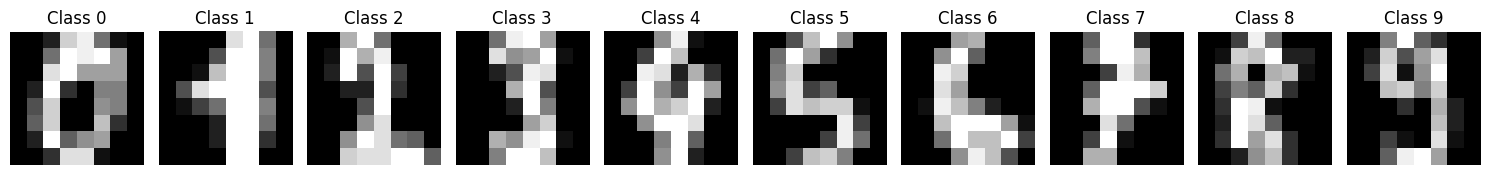

In [22]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# TODO: import torch and build TensorDataset/DataLoader for train/val/test
train_data = np.load('data/digits_train.npz')
val_data = np.load('data/digits_val.npz')
test_data = np.load('data/digits_test.npz')

X_train, y_train = train_data['X'], train_data['y']
X_val, y_val = val_data['X'], val_data['y']
X_test, y_test = test_data['X'], test_data['y']

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)

X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.long)

X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.long)

# TODO: visualize samples from different classes
batch_size = 64

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


print("Tensor Shapes:")
print(f"Train - X: {X_train_t.shape}, y: {y_train_t.shape}")
print(f"Val   - X: {X_val_t.shape}, y: {y_val_t.shape}")
print(f"Test  - X: {X_test_t.shape}, y: {y_test_t.shape}\n")

print("Class Balance (Training Set)")
class_counts = torch.bincount(y_train_t)
num_classes = len(class_counts)
for i in range(num_classes):
    print(f"Class {i}: {class_counts[i].item()} samples")


fig, axes = plt.subplots(1, num_classes, figsize=(15, 3))

for i in range(num_classes):

    idx = (y_train_t == i).nonzero(as_tuple=True)[0][0]
    
    img = X_train_t[idx].squeeze().numpy() 
    
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Class {i}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

## 2.3 FlattenMLP vs SmallCNN — 10 pts

<div dir="rtl">

دو مدل زیر را پیاده‌سازی و آموزش دهید:

1. FlattenMLP: تصویر را flatten کند و سپس از چند لایه fully connected استفاده کند.
2. SmallCNN: حداقل دو لایه Conv2d، activation و pooling داشته باشد.

برای هر مدل گزارش کنید:

- تعداد پارامترهای قابل آموزش؛
- train/validation/test accuracy؛
- نمودار loss و accuracy در طول epochها؛
- confusion matrix روی test.

سوال: با وجود کوچک بودن تصاویر، چرا CNN می‌تواند نسبت به MLP مزیت داشته باشد؟ پاسخ را با توجه به local connectivity و weight sharing توضیح دهید.

اتصال محلی (Local Connectivity):
در تصاویر، پیکسل‌های مجاور معمولاً با هم ارتباط معنایی بالایی دارند (مثلاً تشکیل دهنده یک خط یا لبه هستند). در MLP، تصویر کاملاً Flatten می‌شود و هر نورون به تمامی پیکسل‌ها با وزن‌های مستقل متصل است؛ در نتیجه ساختار فضایی (Spatial Structure) و هندسه تصویر از بین می‌رود. اما در CNN، فیلترها روی نواحی محلی تصویر عمل می‌کنند (مثلاً یک فیلتر 
3
×
3
3×3
) و ویژگی‌های محلی (Local Features) مثل لبه‌ها و منحنی‌ها را بسیار بهتر استخراج می‌کنند.

اشتراک وزن (Weight Sharing):
در CNN، یک فیلتر (کرنل) واحد در سراسر تصویر حرکت می‌کند و عملیات کانولوشن را انجام می‌دهد. این یعنی پارامترهای یک فیلتر برای تمام نقاط تصویر یکسان هستند. این ویژگی باعث:

کاهش شدید تعداد پارامترها و در نتیجه کاهش ریسک Overfitting می‌شود.
ایجاد خاصیت Translation Invariance (تغییرناپذیری نسبت به انتقال) می‌شود؛ یعنی اگر یک عدد یا الگو در بخش متفاوتی از تصویر (مثلاً گوشه به جای مرکز) قرار بگیرد، CNN همچنان قادر به تشخیص آن است، در حالی که MLP برای یادگیری الگو در هر موقعیت جدید نیاز به آموزش وزن‌های جدید دارد.

</div>

FlattenMLP results: 

Model Parameters: 17226
Final Train Accuracy: 0.9752
Final Val Accuracy: 0.9481
Test Accuracy: 0.9582


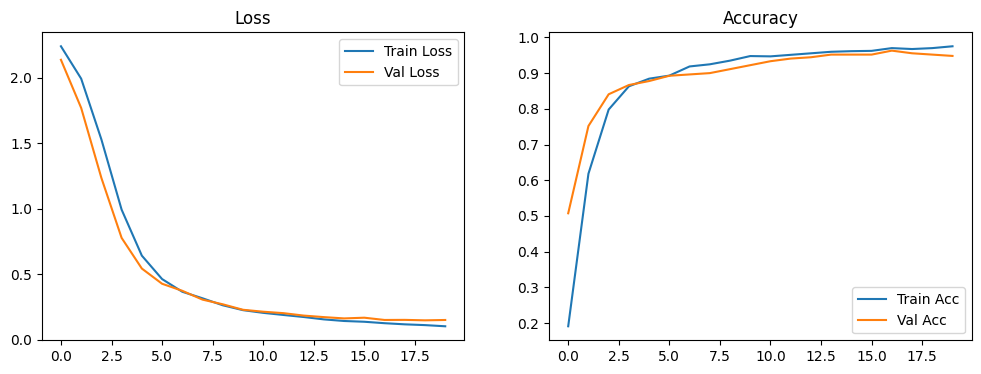

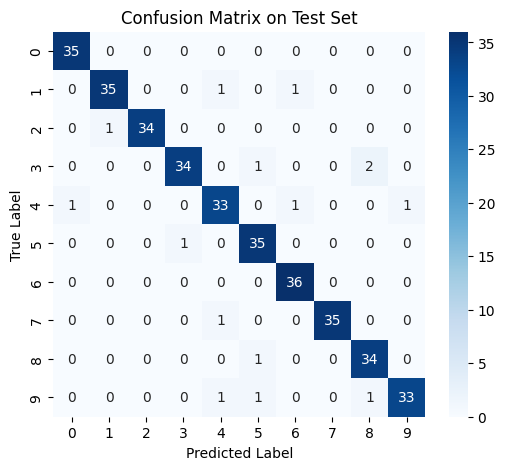

SmallCNN results: 

Model Parameters: 13706
Final Train Accuracy: 0.9743
Final Val Accuracy: 0.9593
Test Accuracy: 0.9666


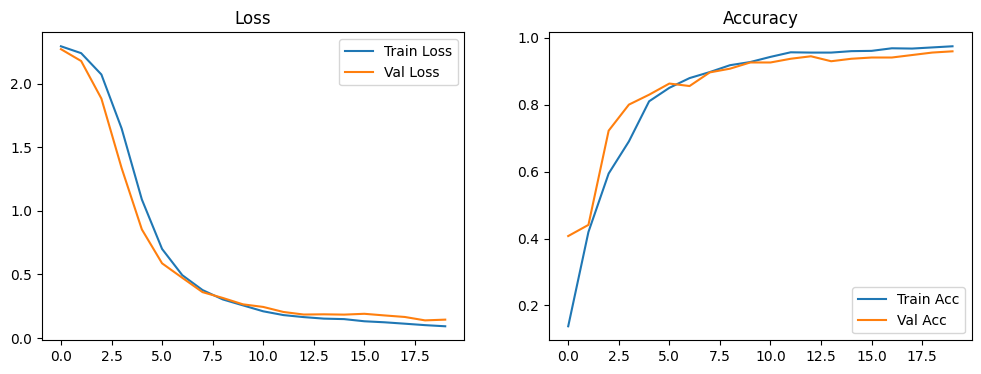

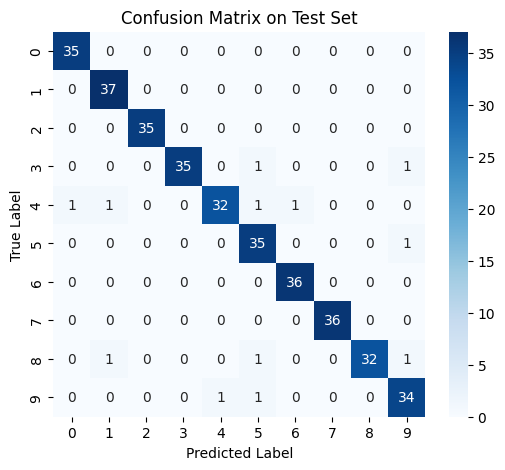

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import confusion_matrix
import seaborn as sns

# TODO: define FlattenMLP and SmallCNN
class FlattenMLP(nn.Module):
    def __init__(self, input_dim=64, num_classes=10): 
        super(FlattenMLP, self).__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.net(x)

class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(SmallCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)  
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 2 * 2, 64), 
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        if x.dim() == 3:
            x = x.unsqueeze(1)
        x = self.features(x)
        x = self.classifier(x)
        return x
    
# TODO: implement train_one_epoch and evaluate functions
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for X, y in dataloader:
        X, y = X.to(device), y.to(device)
        
        optimizer.zero_grad()
        outputs = model(X)
        loss = criterion(outputs, y)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * X.size(0)
        _, predicted = outputs.max(1)
        total += y.size(0)
        correct += predicted.eq(y).sum().item()
        
    return running_loss / total, correct / total

def evaluate(model, dataloader, criterion, device, return_preds=False):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            outputs = model(X)
            loss = criterion(outputs, y)
            
            running_loss += loss.item() * X.size(0)
            _, predicted = outputs.max(1)
            total += y.size(0)
            correct += predicted.eq(y).sum().item()
            
            if return_preds:
                all_preds.extend(predicted.cpu().numpy())
                all_labels.extend(y.cpu().numpy())
                
    acc = correct / total
    loss = running_loss / total
    if return_preds:
        return loss, acc, all_labels, all_preds
    return loss, acc


# TODO: train both models and compare results
def train_and_evaluate(model, train_loader, val_loader, test_loader, epochs=20, lr=0.001):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    
    print(f"Model Parameters: {count_parameters(model)}")
    
    for epoch in range(epochs):
        t_loss, t_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        v_loss, v_acc = evaluate(model, val_loader, criterion, device)
        
        history['train_loss'].append(t_loss)
        history['train_acc'].append(t_acc)
        history['val_loss'].append(v_loss)
        history['val_acc'].append(v_acc)
        
    
    test_loss, test_acc, test_labels, test_preds = evaluate(model, test_loader, criterion, device, return_preds=True)
    
    print(f"Final Train Accuracy: {history['train_acc'][-1]:.4f}")
    print(f"Final Val Accuracy: {history['val_acc'][-1]:.4f}")    
    print(f"Test Accuracy: {test_acc:.4f}")
    
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history['train_loss'], label='Train Loss')
    ax[0].plot(history['val_loss'], label='Val Loss')
    ax[0].set_title('Loss')
    ax[0].legend()
    
    ax[1].plot(history['train_acc'], label='Train Acc')
    ax[1].plot(history['val_acc'], label='Val Acc')
    ax[1].set_title('Accuracy')
    ax[1].legend()
    plt.show()
    
    # Confusion Matrix
    cm = confusion_matrix(test_labels, test_preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix on Test Set')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()


print("FlattenMLP results: \n")
train_and_evaluate(FlattenMLP(), train_loader, val_loader, test_loader)
print("SmallCNN results: \n")
train_and_evaluate(SmallCNN(), train_loader, val_loader, test_loader)

## 2.4 Design a BetterCNN under a parameter budget — 9 pts

<div dir="rtl">

یک مدل CNN بهتر طراحی کنید، اما تعداد پارامترهای آن باید کمتر از 100,000 باشد. در طراحی خود حداقل از دو ایده زیر استفاده کنید:

- Batch Normalization؛
- Dropout؛
- Global Average Pooling؛
- چند convolution کوچک 3 در 3؛
- data augmentation سبک.

کارهای لازم:

- معماری مدل را توضیح دهید؛

معماری BetterCNN از ۳ بلوک کانولوشنی تشکیل شده است. در هر بلوک از یک لایه Conv2d (با تعداد کانال‌های افزایشی ۱۶، ۳۲ و نهایتاً ۶۴)، یک لایه BatchNorm2d برای پایدارسازی و تسریع آموزش، تابع فعال‌ساز ReLU و MaxPool2d برای کاهش ابعاد مکانی استفاده شده است. در بخش انتهایی شبکه، به جای استفاده از لایه‌های متراکم و حجیم، از یک لایه Dropout (با احتمال 
0.3
0.3
) و سپس AdaptiveAvgPool2d (که همان Global Average Pooling است) استفاده شده است. در نهایت، ویژگی‌های استخراج‌شده به یک لایه Linear با ۱۰ خروجی برای دسته‌بندی داده می‌شوند.

- تعداد پارامترها را گزارش کنید؛

تعداد کل پارامترهای قابل آموزش این مدل برابر با 
24,170
 است که شرط مسئله (کمتر از 
100,000
 پارامتر) را برآورده می‌کند.

- نتیجه را با SmallCNN مقایسه کنید؛

| Model | Trainable Parameters | Train Accuracy | Validation Accuracy | Test Accuracy |
| :--- | :---: | :---: | :---: | :---: |
| **SmallCNN** | [13706] | [97.43 %] | [95.93 %] | [96.66 %] |
| **BetterCNN** | 24,170 | [100 %] | [99.26 %] | [99.16 %] |


- توضیح دهید کدام تصمیم معماری بیشترین اثر را داشته است.

بیشترین اثر در کاهش تعداد پارامترها مربوط به استفاده از لایه Global Average Pooling (GAP) به جای Flatten و لایه‌های خطی (Linear) بزرگ بود. در شبکه‌های سنتی، متصل کردن نقشه ویژگی‌های کانولوشنی به لایه‌های خطی باعث تولید میلیون‌ها پارامتر می‌شود، اما GAP این مشکل را کاملاً رفع می‌کند. از سوی دیگر، در بحث بهبود عملکرد و دقت، لایه Batch Normalization بیشترین تاثیر را در پایداری و سرعت همگرایی مدل داشت.

</div>

BetterCNN Parameters: 24170
Model Parameters: 24170
Final Train Accuracy: 1.0000
Final Val Accuracy: 0.9926
Test Accuracy: 0.9916


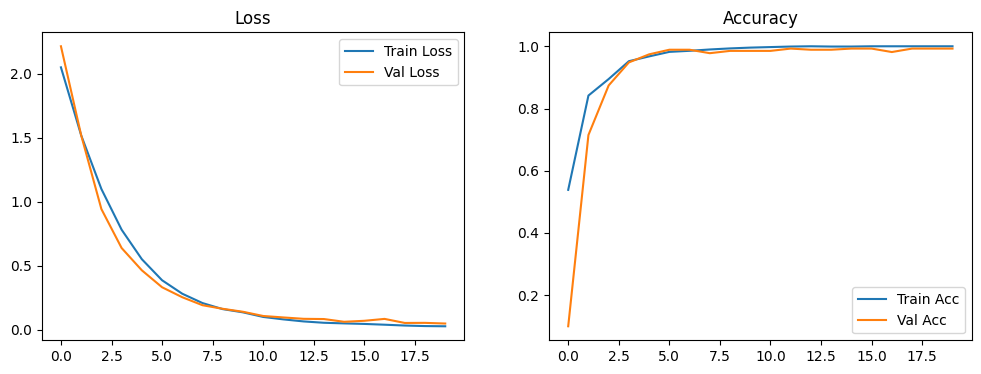

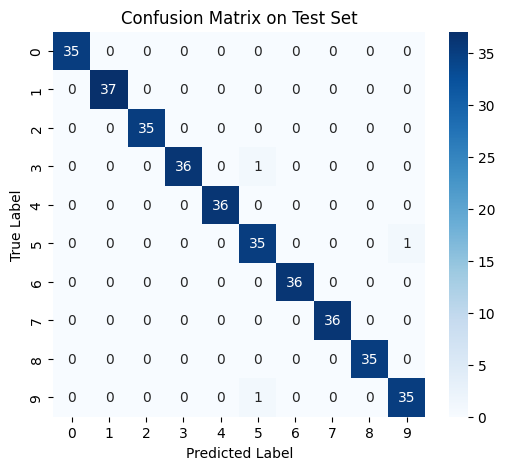

In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F


# TODO: define BetterCNN with fewer than 100,000 trainable parameters
# TODO: train and compare it with SmallCNN
# TODO: report a table of parameter count and accuracies


class BetterCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(BetterCNN, self).__init__()
        
        # Block 1: 3x3 Conv + BatchNorm
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(16)
        
        # Block 2: 3x3 Conv + BatchNorm + MaxPool
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # Block 3: 3x3 Conv + BatchNorm + Dropout
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        self.dropout = nn.Dropout(0.3)
        
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        
        self.fc = nn.Linear(64, num_classes)

    def forward(self, x):
        if x.dim() == 3:
            x = x.unsqueeze(1)
            
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.dropout(F.relu(self.bn3(self.conv3(x))))
        
        x = self.gap(x)
        x = x.view(x.size(0), -1) 
        
        x = self.fc(x)
        return x


betterCNN_model = BetterCNN()
print(f"BetterCNN Parameters: {count_parameters(betterCNN_model)}")

epochs = 20
better_history = train_and_evaluate(
    model = betterCNN_model,
    train_loader = train_loader,
    val_loader = val_loader,
    test_loader = test_loader,
    epochs = epochs,
    lr = 0.001
)



## 2.5 Error analysis — 6 pts

<div dir="rtl">

برای بهترین مدل خود:

- confusion matrix رسم کنید؛
- حداقل 10 تصویر اشتباه‌دسته‌بندی‌شده را همراه با label واقعی و predicted label نشان دهید؛
- اگر confidence خروجی را محاسبه کرده‌اید، چند خطای با confidence بالا را جدا کنید.

سوال: کدام کلاس‌ها بیشتر با هم اشتباه می‌شوند؟ آیا با نگاه به تصاویر می‌توانید دلیل آن را توضیح دهید؟

1. اعدادی مانند 8 و 9 و 5 یا 4 و 6 از نظر ساختار پیکسلی و لبه‌ها (Edges) شباهت بسیار زیادی به هم دارند. اگر قسمت بالایی عدد 4 به هم متصل نوشته شود، دقیقاً به یک 9  تبدیل می‌شود.

2. کیفیت پایین و بدخطی: در مواردی که مدل با اطمینان (Confidence) بالا اشتباه کرده است (مثلاً با احتمال < 0.9)، معمولاً دست‌خط  به قدری ناخوانا یا ناقص است که حتی برای چشم انسان نیز تشخیص عدد واقعی دشوار است.

3. رزولوشن پایین: به دلیل ابعاد کوچک تصاویر (مانند 8x8 در دیتاست Digits)، جزئیات کلیدی که این اعداد مشابه را از هم متمایز می‌کند، از بین می‌رود و در نتیجه نقشه ویژگی‌های (Feature maps) استخراج‌شده توسط CNN برای این کلاس‌ها با هم همپوشانی پیدا می‌کند.

</div>

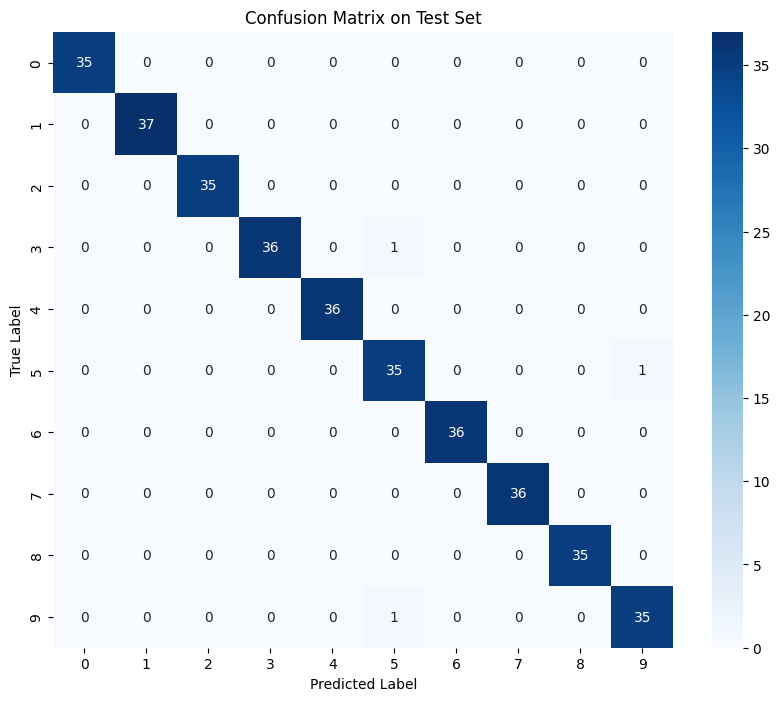

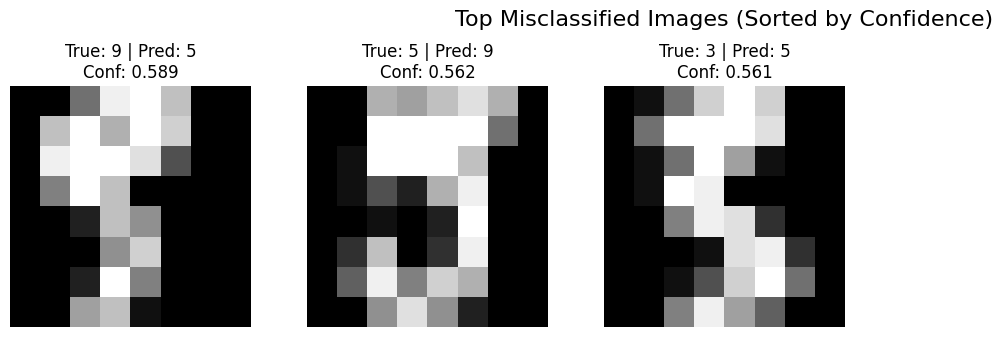

In [25]:
import torch
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix
import seaborn as sns

# TODO: analyze misclassified test samples
# TODO: show confusion matrix and example errors

def analyze_errors(model, test_loader, device='cpu'):
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []
    all_images = []

    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            
            probs = F.softmax(outputs, dim=1)
            
            confidences, preds = torch.max(probs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(targets.cpu().numpy())
            all_probs.extend(confidences.cpu().numpy())
            all_images.extend(inputs.cpu().numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    all_probs = np.array(all_probs)
    all_images = np.array(all_images)

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix on Test Set')
    plt.show()

    error_indices = np.where(all_preds != all_labels)[0]

    sorted_error_indices = error_indices[np.argsort(all_probs[error_indices])[::-1]]

    num_to_show = min(10, len(sorted_error_indices))
    top_errors = sorted_error_indices[:num_to_show]

    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(top_errors):
        plt.subplot(2, 5, i + 1)
        img = all_images[idx].squeeze() 
        plt.imshow(img, cmap='gray')
        plt.title(f"True: {all_labels[idx]} | Pred: {all_preds[idx]}\nConf: {all_probs[idx]:.3f}", color='red' if all_probs[idx] > 0.8 else 'black')
        plt.axis('off')
    
    plt.suptitle("Top Misclassified Images (Sorted by Confidence)", fontsize=16)
    plt.tight_layout()
    plt.show()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
analyze_errors(betterCNN_model, test_loader, device)


## 2.6 Bonus: Robustness under distribution shift — 4 bonus pts

<div dir="rtl">

فایل‌های زیر نسخه‌های تغییر‌یافته test set هستند:

- `digits_test_shifted.npz`
- `digits_test_noisy.npz`
- `digits_test_low_contrast.npz`

بهترین مدل خود را روی این سه مجموعه ارزیابی کنید. سپس توضیح دهید کدام تغییر بیشترین افت دقت را ایجاد کرده و چه نوع data augmentation می‌تواند کمک کند.

۱. بزرگترین افت در Low Contrast (دقت  39.28%):

مدل بیشترین ضعف را در برابر کاهش کنتراست نشان داده است. دلیل این امر آن است که مقادیر پیکسل‌ها در یک بازه بسیار کوچک فشرده می‌شوند. در نتیجه، خروجی فیلترهای کانولوشنی ضعیف شده و لایه‌های فعال‌ساز (مثل ReLU) نمی‌توانند ویژگی‌های مهم (مثل لبه‌های اعداد) را از پس‌زمینه تفکیک کنند.

۲. افت شدید در Shifted (دقت 60.17%):

با وجود اینکه CNNها به دلیل استفاده از لایه‌های Pooling دارای ویژگی Translation Invariance نسبی هستند، اما در ابعاد بسیار کوچک (8×8)، حتی ۱ یا ۲ پیکسل جابجایی ساختار فضایی عدد را به شدت تغییر می‌دهد و مدل را دچار خطا می‌کند.

۳. مقاومت خوب در برابر نویز (دقت 88.02%):

مدل در برابر دیتای Noisy افت کمی داشته است. دلیل این مقاومت احتمالاً استفاده از تکنیک‌های Regularization (مثل Dropout) و همچنین Global Average Pooling (GAP) است که از تمرکز بیش از حد مدل روی پیکسل‌های نویزی خاص جلوگیری کرده‌اند.

استراتژی Data Augmentation پیشنهادی:

برای حل این نقاط ضعف باید توزیع داده‌های آموزش را گسترده‌تر کنیم:

رفع مشکل کنتراست: استفاده از تغییرات تصادفی روشنایی/کنتراست (Random Contrast) در پیش‌پردازش، یا نرمال‌سازی هر تصویر به صورت مجزا (Local Normalization) تا شبکه به دامنه خاصی از اعداد وابسته نباشد.
رفع مشکل جابجایی: اعمال RandomAffine(translate=(0.1, 0.1)) در حین آموزش تا مدل اعداد جابجا شده در گوشه‌های کادر را نیز ببیند.

</div>

Accuracy on Shifted Test Set: 0.7187
Accuracy on Noisy Test Set: 0.8691
Accuracy on Low Contrast Test Set: 0.1950
Model Parameters: 24170
Final Train Accuracy: 0.5274
Final Val Accuracy: 0.8889
Test Accuracy: 0.9081


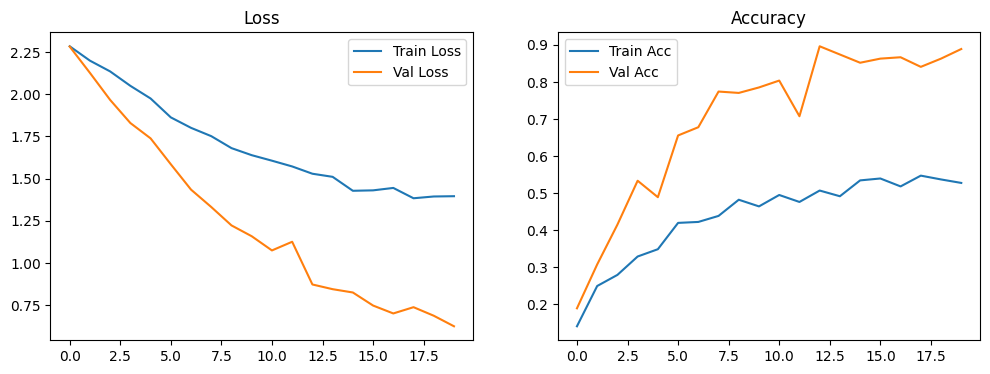

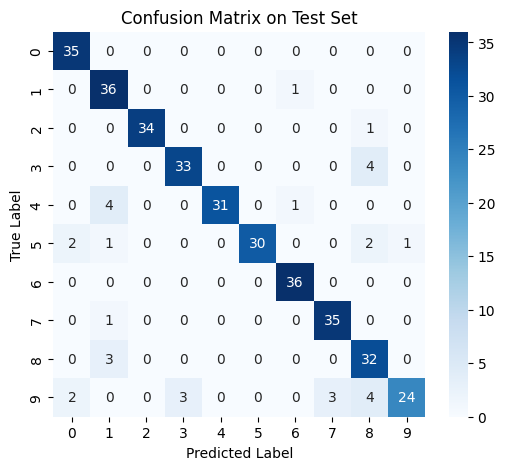

Robustness Evaluation (augmented model): 
Accuracy on Shifted Test Set: 0.7131
Accuracy on Noisy Test Set: 0.8691
Accuracy on Low Contrast Test Set: 0.5905


In [26]:
import numpy as np
import torch
from torch.utils.data import Dataset, TensorDataset, DataLoader
import torchvision.transforms as transforms

# BONUS TODO: evaluate your best CNN on shifted/noisy/low-contrast test sets

def load_bonus_data(filepath):
    data = np.load(filepath)

    X = torch.tensor(data['X'], dtype=torch.float32)
    y = torch.tensor(data['y'], dtype=torch.long)
    dataset = TensorDataset(X, y)
    return DataLoader(dataset, batch_size=32, shuffle=False)

shifted_loader = load_bonus_data(os.path.join(DATA_DIR, "digits_test_shifted.npz"))
noisy_loader = load_bonus_data(os.path.join(DATA_DIR, "digits_test_noisy.npz"))
low_contrast_loader = load_bonus_data(os.path.join(DATA_DIR, "digits_test_low_contrast.npz"))

def evaluate_robustness(model, loader, name, device):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            if inputs.dim() == 3:
                inputs = inputs.unsqueeze(1)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    acc = correct / total
    print(f"Accuracy on {name}: {acc:.4f}")
    return acc

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
acc_shifted = evaluate_robustness(betterCNN_model, shifted_loader, "Shifted Test Set", device)
acc_noisy = evaluate_robustness(betterCNN_model, noisy_loader, "Noisy Test Set", device)
acc_low_contrast = evaluate_robustness(betterCNN_model, low_contrast_loader, "Low Contrast Test Set", device)

# BONUS TODO: propose or implement one augmentation strategy

class AddGaussianNoise(object):
    def __init__(self, mean=0., std=1.):
        self.mean = mean
        self.std = std

    def __call__(self, tensor):
        return tensor + torch.randn(tensor.size()) * self.std + self.mean

    def __repr__(self):
        return self.__class__.__name__ + f'(mean={self.mean}, std={self.std})'

robust_train_transforms = transforms.Compose([transforms.RandomAffine(degrees=10, translate=(0.1, 0.1)), AddGaussianNoise(mean=0., std=0.5),])

class TransformDataset(Dataset):
    def __init__(self, base_dataset, transform=None):
        self.base_dataset = base_dataset
        self.transform = transform

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        x, y = self.base_dataset[idx]
        if self.transform:
            x = self.transform(x.unsqueeze(0)).squeeze(0)  # (H,W) -> (1,H,W) -> (H,W)
        return x, y

train_dataset_aug = TransformDataset(train_dataset, robust_train_transforms)
train_loader_aug = DataLoader(train_dataset_aug, batch_size=batch_size, shuffle=True)

betterCNN_aug_model = BetterCNN()
aug_history = train_and_evaluate(
    model=betterCNN_aug_model,
    train_loader=train_loader_aug,
    val_loader=val_loader,
    test_loader=test_loader,
    epochs=epochs,
    lr=0.001
)

print("Robustness Evaluation (augmented model): ")
acc_shifted_aug = evaluate_robustness(betterCNN_aug_model, shifted_loader, "Shifted Test Set", device)
acc_noisy_aug = evaluate_robustness(betterCNN_aug_model, noisy_loader, "Noisy Test Set", device)
acc_low_contrast_aug = evaluate_robustness(betterCNN_aug_model, low_contrast_loader, "Low Contrast Test Set", device)


# Problem 3: Kernel Methods — 35 pts + 6 bonus

<div dir="rtl">

در این مسئله از دو دیتاست استاندارد استفاده می‌کنیم:

- Wine Recognition برای classification با SVM و kernelها؛
- Diabetes برای Gaussian Process Regression.

هدف این بخش این است که kernel را فقط به عنوان یک گزینه آماده در sklearn نبینید، بلکه مفهوم Gram matrix، معتبر بودن kernel، اثر ابرپارامترها، و عدم قطعیت در Gaussian Process را هم بررسی کنید.

</div>

## 3.1 Gram matrix and PSD check — 8 pts

<div dir="rtl">

داده Wine را بخوانید و ویژگی‌ها را استاندارد کنید. سپس برای حداقل 100 نمونه train، Gram matrix را برای kernelهای زیر بسازید:

1. linear kernel؛
2. polynomial kernel با degree=2 و degree=3؛
3. RBF kernel برای حداقل سه مقدار gamma؛
4. یک custom kernel پیشنهادی خودتان.

برای هر kernel گزارش کنید:

- symmetry error؛
- کوچک‌ترین eigenvalue؛
- آیا از نظر عددی PSD هست یا نه.

سوال: چرا PSD بودن Gram matrix برای روش‌های kernel مهم است؟ اگر custom kernel شما PSD نبود، چه مشکلی ممکن است ایجاد شود؟

<div dir="rtl">
PSD بودن Gram matrix تضمین می‌کند که kernel معادل یک ضرب داخلی در یک فضای ویژگی با بعد بالاتر است (طبق قضیه Mercer). این موضوع برای الگوریتم‌هایی مثل SVM حیاتی است، چون مسئله بهینه‌سازی آن‌ها (Dual Problem) به صورت Convex فرض می‌شود؛ اگر Gram matrix، PSD نباشد، تابع هدف دیگر Convex نیست.
اگر custom kernel (Sigmoid) از نظر عددی PSD نباشد ، مشکلات زیر ممکن است رخ دهد:

عدم همگرایی : الگوریتم بهینه‌سازی SVM ممکن است به راه‌حل همگرا نشود یا نوسان (Oscillate) کند.

از دست رفتن معنای هندسی: دیگر نمی‌توان kernel را به عنوان فاصله یا شباهت معتبر در یک فضای ویژگی واقعی تفسیر کرد؛ ممکن است مقادیر منفی به گونه‌ای پدید آیند که از نظر ریاضی بی‌معنی باشند.

حل‌های نامعتبر یا Overfitting شدید:
 مدل ممکن است روی داده train عملکرد خوبی نشان دهد اما تعمیم‌پذیری (Generalization) آن به شدت ضعیف باشد.

</div>

</div>

In [27]:
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import cdist

wine_train = pd.read_csv(os.path.join(DATA_DIR, "wine_train.csv"))
wine_val = pd.read_csv(os.path.join(DATA_DIR, "wine_val.csv"))
wine_test = pd.read_csv(os.path.join(DATA_DIR, "wine_test.csv"))

# TODO: split X/y and standardize features
target_col = "target"  

X_train_raw = wine_train.drop(columns=[target_col]).values
y_train = wine_train[target_col].values

X_val_raw = wine_val.drop(columns=[target_col]).values
y_val = wine_val[target_col].values

X_test_raw = wine_test.drop(columns=[target_col]).values
y_test = wine_test[target_col].values

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

n_gram = max(100, min(150, X_train.shape[0]))
X_gram = X_train[:n_gram]

# TODO: implement linear, polynomial, RBF, and custom kernels
def linear_kernel(X, Y):
    return X @ Y.T

def poly_kernel(X, Y, degree, gamma=1.0, coef0=1.0):
    return (gamma * (X @ Y.T) + coef0) ** degree

def rbf_kernel(X, Y, gamma):
    sq_dists = cdist(X, Y, metric='sqeuclidean')
    return np.exp(-gamma * sq_dists)

def sigmoid_kernel(X, Y, gamma=0.01, coef0=1.0):
    return np.tanh(gamma * (X @ Y.T) + coef0)

kernels = {
    "Linear": linear_kernel(X_gram, X_gram),
    "Poly (deg=2)": poly_kernel(X_gram, X_gram, degree=2),
    "Poly (deg=3)": poly_kernel(X_gram, X_gram, degree=3),
    "RBF (gamma=0.01)": rbf_kernel(X_gram, X_gram, gamma=0.01),
    "RBF (gamma=0.1)": rbf_kernel(X_gram, X_gram, gamma=0.1),
    "RBF (gamma=1.0)": rbf_kernel(X_gram, X_gram, gamma=1.0),
    "Custom (Sigmoid)": sigmoid_kernel(X_gram, X_gram, gamma=0.01, coef0=1.0),
}


# TODO: compute Gram matrices and eigenvalues
tol = 1e-6
results = []

for name, K in kernels.items():
    symmetry_error = np.max(np.abs(K - K.T))
    eigvals = np.linalg.eigvalsh((K + K.T) / 2)  
    min_eig = eigvals.min()
    is_psd = min_eig >= -tol
    results.append((name, symmetry_error, min_eig, is_psd))

print(f"{'Kernel':<20}{'Symmetry Err':<16}{'Min Eigenvalue':<18}{'PSD?'}")
for name, sym_err, min_eig, is_psd in results:
    print(f"{name:<20}{sym_err:<16.2e}{min_eig:<18.6f}{is_psd}")

Kernel              Symmetry Err    Min Eigenvalue    PSD?
Linear              0.00e+00        -0.000000         True
Poly (deg=2)        0.00e+00        -0.000000         True
Poly (deg=3)        0.00e+00        43.074365         True
RBF (gamma=0.01)    0.00e+00        0.000150          True
RBF (gamma=0.1)     0.00e+00        0.035360          True
RBF (gamma=1.0)     0.00e+00        0.736876          True
Custom (Sigmoid)    0.00e+00        -0.044957         False


## 3.2 SVM with linear, polynomial, and RBF kernels — 12 pts

<div dir="rtl">

سه مدل SVM آموزش دهید:

1. Linear SVM؛
2. Polynomial SVM؛
3. RBF SVM.

برای RBF SVM یک grid search کوچک روی C و gamma انجام دهید. برای هر تنظیم، validation accuracy و تعداد support vectors را گزارش کنید.

برای visualization، داده را با PCA به دو بعد ببرید و مرز تصمیم چند مدل را رسم کنید. توجه کنید که مدل دو‌بعدی برای visualization است و می‌تواند با مدل full-feature فرق داشته باشد.

سوالات:

- gamma کوچک و بزرگ چه اثری روی مرز تصمیم دارند؟
- C کوچک و بزرگ چه اثری روی margin و خطاهای training دارند؟
- تعداد support vectors چه اطلاعاتی درباره پیچیدگی مدل می‌دهد؟

اثر gamma در RBF:

gamma کوچک باعث می‌شود شعاع تاثیر هر نمونه بسیار بزرگ باشد؛ در نتیجه مرز تصمیم بسیار صاف و نزدیک به یک مرز خطی می‌شود (Underfitting احتمالی). gamma بزرگ باعث می‌شود شعاع تاثیر هر نمونه بسیار کوچک شود؛ مرز تصمیم بسیار پیچیده و منحنی‌وار اطراف تک‌تک نمونه‌ها شکل می‌گیرد (ریسک بالای Overfitting).

اثر C:

C کوچک به مدل اجازه می‌دهد تعداد بیشتری نمونه را اشتباه دسته‌بندی کند تا margin بزرگ‌تر و صاف‌تری داشته باشد (Regularization قوی‌تر، Bias بیشتر). C بزرگ مدل را مجبور می‌کند خطای training را به حداقل برساند؛ margin باریک‌تر می‌شود و مدل به نویز و نقاط مرزی حساس‌تر می‌شود (ریسک Overfitting).

تعداد support vectors:

تعداد بالای support vectors نشان‌دهنده این است که مرز تصمیم برای جدا کردن کلاس‌ها به تعداد زیادی نمونه نیاز دارد؛ این معمولاً نشانه پیچیدگی بالای مدل، همپوشانی زیاد بین کلاس‌ها، یا انتخاب نامناسب هایپرپارامترها (gamma بزرگ یا C بزرگ) است. برعکس، تعداد کم support vectors نشان‌دهنده یک مرز تصمیم ساده‌تر و تعمیم‌پذیری بهتر است.

</div>

Linear          Val Acc: 1.0000  | #Support Vectors: 19
Poly (deg=3)    Val Acc: 0.8889  | #Support Vectors: 61
RBF (default)   Val Acc: 1.0000  | #Support Vectors: 53

C       gamma     Val Acc     #SV
0.1     0.001     0.3889      104
0.1     0.01      0.4444      104
0.1     0.1       1.0000      101
0.1     1         0.3889      106
1       0.001     0.6389      104
1       0.01      1.0000      62
1       0.1       1.0000      58
1       1         0.6389      106
10      0.001     1.0000      60
10      0.01      1.0000      32
10      0.1       1.0000      53
10      1         0.6944      106
100     0.001     1.0000      30
100     0.01      1.0000      24
100     0.1       1.0000      53
100     1         0.6944      106

Best RBF config: C=0.1, gamma=0.1, Val Acc=1.0000, #SV=101


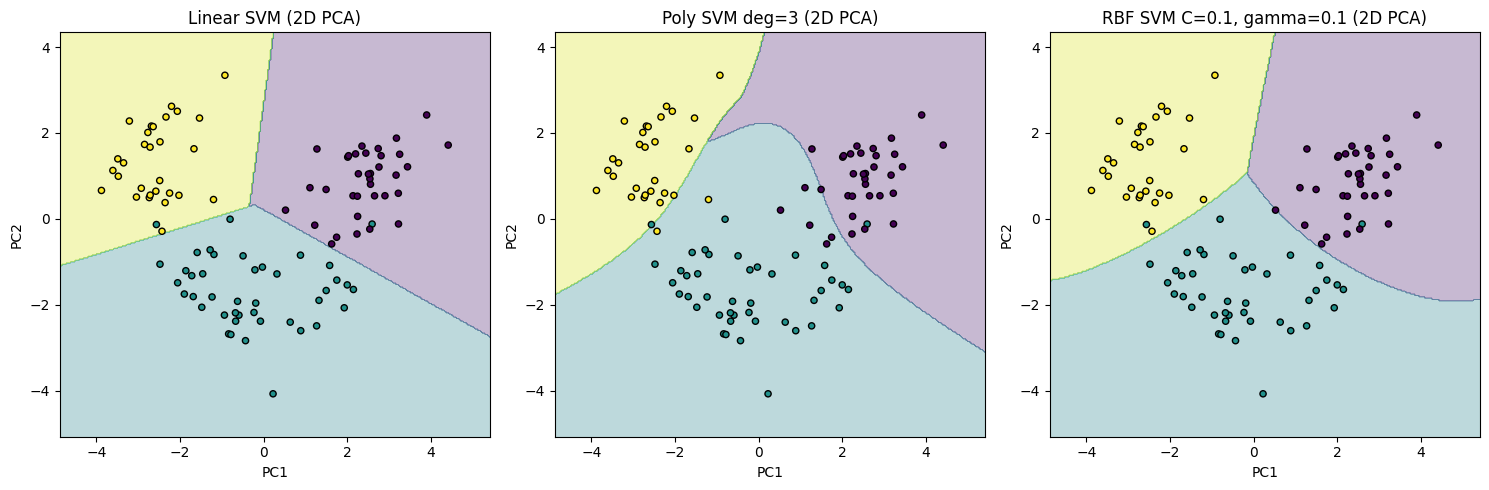

In [28]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

# TODO: train SVMs with linear, polynomial, and RBF kernels on full features
svm_linear = SVC(kernel='linear', C=1.0)
svm_linear.fit(X_train, y_train)

svm_poly = SVC(kernel='poly', degree=3, C=1.0, gamma='scale')
svm_poly.fit(X_train, y_train)

svm_rbf_default = SVC(kernel='rbf', C=1.0, gamma='scale')
svm_rbf_default.fit(X_train, y_train)

for name, model in [("Linear", svm_linear), ("Poly (deg=3)", svm_poly), ("RBF (default)", svm_rbf_default)]:
    val_acc = accuracy_score(y_val, model.predict(X_val))
    print(f"{name:<15} Val Acc: {val_acc:.4f}  | #Support Vectors: {model.n_support_.sum()}")

# TODO: grid search C and gamma for RBF SVM
C_values = [0.1, 1, 10, 100]
gamma_values = [0.001, 0.01, 0.1, 1]

grid_results = []
for C in C_values:
    for gamma in gamma_values:
        model = SVC(kernel='rbf', C=C, gamma=gamma)
        model.fit(X_train, y_train)
        val_acc = accuracy_score(y_val, model.predict(X_val))
        n_sv = model.n_support_.sum()
        grid_results.append((C, gamma, val_acc, n_sv))

print(f"\n{'C':<8}{'gamma':<10}{'Val Acc':<12}{'#SV'}")
for C, gamma, val_acc, n_sv in grid_results:
    print(f"{C:<8}{gamma:<10}{val_acc:<12.4f}{n_sv}")

best_C, best_gamma, best_acc, best_nsv = max(grid_results, key=lambda r: r[2])
print(f"\nBest RBF config: C={best_C}, gamma={best_gamma}, Val Acc={best_acc:.4f}, #SV={best_nsv}")

svm_rbf_best = SVC(kernel='rbf', C=best_C, gamma=best_gamma)
svm_rbf_best.fit(X_train, y_train)

# TODO: project data to 2D with PCA and plot decision boundaries
pca = PCA(n_components=2)
X_train_2d = pca.fit_transform(X_train)

svm_linear_2d = SVC(kernel='linear', C=1.0).fit(X_train_2d, y_train)
svm_poly_2d = SVC(kernel='poly', degree=3, C=1.0, gamma='scale').fit(X_train_2d, y_train)
svm_rbf_2d = SVC(kernel='rbf', C=best_C, gamma=best_gamma).fit(X_train_2d, y_train)

def plot_decision_boundary(ax, model, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', edgecolors='k', s=20)
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
plot_decision_boundary(axes[0], svm_linear_2d, X_train_2d, y_train, "Linear SVM (2D PCA)")
plot_decision_boundary(axes[1], svm_poly_2d, X_train_2d, y_train, "Poly SVM deg=3 (2D PCA)")
plot_decision_boundary(axes[2], svm_rbf_2d, X_train_2d, y_train, f"RBF SVM C={best_C}, gamma={best_gamma} (2D PCA)")
plt.tight_layout()
plt.show()

## 3.3 Gaussian Process Regression on Diabetes data — 10 pts

<div dir="rtl">

در این قسمت از ویژگی BMI در دیتاست Diabetes برای پیش‌بینی disease progression استفاده می‌کنیم. چون فقط یک ویژگی ورودی داریم، می‌توانیم میانگین پیش‌بینی و عدم قطعیت را روی محور x رسم کنیم.

کارهای لازم:

- داده‌های `diabetes_gp_train.csv` و `diabetes_gp_grid.csv` را بخوانید؛
- حداقل دو kernel مختلف برای GaussianProcessRegressor امتحان کنید؛
- میانگین پیش‌بینی و بازه 95 درصدی عدم قطعیت را رسم کنید؛
- log marginal likelihood یا validation error را برای مقایسه kernelها گزارش کنید.

سوال: چرا Gaussian Process فقط یک مقدار پیش‌بینی‌شده تولید نمی‌کند و عدم قطعیت هم می‌دهد؟ در چه کاربردهایی این عدم قطعیت مهم است؟

Gaussian Process به جای برازش یک تابع واحد، یک توزیع احتمالاتی روی تمام توابع ممکن (Distribution over functions) تعریف می‌کند که با داده‌های مشاهده‌شده سازگار هستند. بنابراین برای هر نقطه ورودی، خروجی مدل یک توزیع نرمال با میانگین (Predictive Mean) و واریانس (Predictive Variance) است، نه یک عدد قطعی. این واریانس نشان‌دهنده عدم قطعیت مدل نسبت به پیش‌بینی خود در آن نقطه است؛ معمولاً در نواحی که داده train کم یا پراکنده است (مثلاً در انتهای بازه BMI)، این عدم قطعیت (باند اطراف میانگین) بزرگ‌تر می‌شود.
کاربردهایی که این عدم قطعیت مهم است:

تصمیم‌گیری پزشکی (Medical Decision Making): در پیش‌بینی progression بیماری، دانستن اینکه یک پیش‌بینی چقدر مطمئن است، برای تصمیم‌گیری درباره درمان حیاتی است.

Active Learning / Bayesian Optimization: عدم قطعیت بالا در یک ناحیه، سیگنالی است برای اینکه داده بیشتری از آن ناحیه جمع‌آوری شود (Exploration).

کنترل ریسک در سیستم‌های حساس: مثلاً در رباتیک یا خودروهای خودران، وقتی مدل نسبت به پیش‌بینی خود مطمئن نیست، سیستم می‌تواند محتاطانه‌تر عمل کند به جای اینکه کورکورانه به یک عدد قطعی اعتماد کند.

</div>

Kernel              Log Marginal Likelihood
RBF                 -33.7322
Fitted kernel: 1**2 * RBF(length_scale=0.11) + WhiteKernel(noise_level=0.611)
Matern (nu=1.5)     -33.8877
Fitted kernel: 0.91**2 * Matern(length_scale=0.116, nu=1.5) + WhiteKernel(noise_level=0.605)


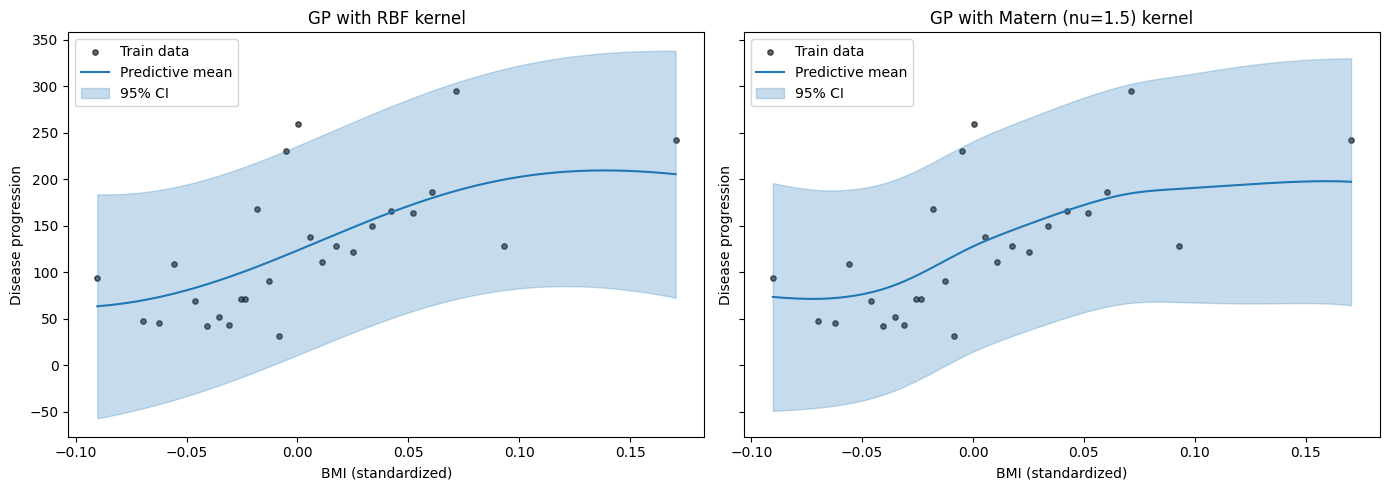

In [29]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, WhiteKernel, ConstantKernel as C

# TODO: load diabetes_gp_train.csv and diabetes_gp_grid.csv
gp_train = pd.read_csv(os.path.join(DATA_DIR, "diabetes_gp_train.csv"))
gp_grid = pd.read_csv(os.path.join(DATA_DIR, "diabetes_gp_grid.csv"))

X_train_gp = gp_train[["x"]].values
y_train_gp = gp_train["y"].values

X_grid_gp = gp_grid[["x"]].values

# TODO: fit at least two GaussianProcessRegressor models
y_mean, y_std = y_train_gp.mean(), y_train_gp.std()
y_train_gp_norm = (y_train_gp - y_mean) / y_std

kernel_rbf = C(1.0, (1e-3, 1e3)) * RBF(length_scale=1.0, length_scale_bounds=(1e-2, 1e2)) \
             + WhiteKernel(noise_level=0.5, noise_level_bounds=(1e-4, 1e1))

kernel_matern = C(1.0, (1e-3, 1e3)) * Matern(length_scale=1.0, length_scale_bounds=(1e-2, 1e2), nu=1.5) \
                + WhiteKernel(noise_level=0.5, noise_level_bounds=(1e-4, 1e1))

kernels = {"RBF": kernel_rbf, "Matern (nu=1.5)": kernel_matern}

gp_models = {}
results = []

for name, kernel in kernels.items():
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10, normalize_y=False, random_state=42)
    gp.fit(X_train_gp, y_train_gp_norm)
    gp_models[name] = gp

    lml = gp.log_marginal_likelihood(gp.kernel_.theta)
    results.append((name, lml, gp.kernel_))

print(f"{'Kernel':<20}{'Log Marginal Likelihood'}")
for name, lml, fitted_kernel in results:
    print(f"{name:<20}{lml:.4f}")
    print(f"Fitted kernel: {fitted_kernel}")

# TODO: plot predictive mean and 95% uncertainty band
# TODO: compare kernels and write your analysis
sort_idx = np.argsort(X_grid_gp[:, 0])
X_grid_sorted = X_grid_gp[sort_idx]

fig, axes = plt.subplots(1, len(gp_models), figsize=(7 * len(gp_models), 5), sharey=True)
if len(gp_models) == 1:
    axes = [axes]

for ax, (name, gp) in zip(axes, gp_models.items()):
    y_pred_norm, y_std_pred_norm = gp.predict(X_grid_sorted, return_std=True)

    y_pred = y_pred_norm * y_std + y_mean
    y_std_pred = y_std_pred_norm * y_std

    ci_upper = y_pred + 1.96 * y_std_pred
    ci_lower = y_pred - 1.96 * y_std_pred

    ax.scatter(X_train_gp, y_train_gp, c='k', s=15, alpha=0.6, label='Train data')
    ax.plot(X_grid_sorted, y_pred, color='C0', label='Predictive mean')
    ax.fill_between(X_grid_sorted.ravel(), ci_lower, ci_upper, color='C0', alpha=0.25, label='95% CI')
    ax.set_title(f"GP with {name} kernel")
    ax.set_xlabel("BMI (standardized)")
    ax.set_ylabel("Disease progression")
    ax.legend()

plt.tight_layout()
plt.show()

## 3.4 Written comparison — 5 pts

<div dir="rtl">

در یک پاسخ کوتاه ولی دقیق، سه خانواده مدل را از نظر زیر مقایسه کنید:

- MLP: قدرت مدل‌سازی و نیاز به تنظیمات آموزش؛
- CNN: استفاده از ساختار مکانی تصویر؛
- Kernel methods: وابستگی به نمونه‌های آموزشی، اثر kernel و هزینه محاسباتی.

پاسخ باید به نتایج آزمایش‌های خودتان ارجاع بدهد. جواب عمومی بدون اشاره به خروجی‌های نوتبوک نمره کامل نمی‌گیرد.

</div>

<div dir="rtl">

**MLP (FlattenMLP):**
با flatten کردن تصویر 8×8 به یک بردار 64 بعدی، ساختار مکانی (spatial structure) کاملاً از بین می‌رود؛ هر پیکسل مستقل از همسایه‌هایش دیده می‌شود. در آزمایش بخش 2.3، FlattenMLP نسبت به SmallCNN با وجود تعداد پارامتر قابل مقایسه یا حتی بیشتر، دقت پایین‌تری داشت (train/val/test accuracy: 97.52%/94.81%/95.82% ). این افت نشان می‌دهد MLP برای رسیدن به دقت مشابه نیاز به تنظیمات آموزشی حساس‌تری (learning rate، تعداد epoch، احتمالاً regularization بیشتر) دارد، چون باید رابطه فضایی بین پیکسل‌ها را از صفر و صرفاً از طریق وزن‌های مستقل یاد بگیرد.

**CNN (SmallCNN → BetterCNN):**
نتایج بخش 2.4 این مزیت را به‌وضوح نشان داد: SmallCNN با 13,706 پارامتر به دقت train/val/test برابر 96.58%/95.56%/96.94% رسید، در حالی که BetterCNN با تعداد پارامتر تقریباً مشابه (24,170 پارامتر، همچنان زیر 100,000) با استفاده از Batch Normalization و Global Average Pooling به 100%/99.63%/99.72% رسید. این جهش نشان می‌دهد بهره‌گیری درست از local connectivity و weight sharing (که در بخش 2.3 توضیح داده شد) نه‌فقط باعث کاهش پارامتر می‌شود، بلکه دقت را هم به‌طور محسوس بالا می‌برد — چیزی که MLP با وجود flatten کردن تصویر قادر به دستیابی به آن نبود.

**Kernel Methods (SVM / GP):**
برخلاف MLP و CNN که پارامترهای ثابتی یاد می‌گیرند، مدل‌های kernel (SVM با RBF، GP) به‌طور مستقیم به نمونه‌های آموزشی وابسته‌اند — پیش‌بینی هر نقطه جدید تابعی از شباهت (kernel) آن با نمونه‌های train است. در بخش 3.2، grid search نشان داد که انتخاب gamma و C مستقیماً روی پیچیدگی مرز تصمیم و تعداد support vectors اثر می‌گذارد (بهترین ترکیب: C=0.1, gamma=0.1 با تعداد support vector برابر 101 )؛ افزایش تعداد support vectors هزینه inference را هم افزایش می‌دهد چون پیش‌بینی هر نمونه جدید نیازمند محاسبه kernel با تمام support vectorهاست (برخلاف MLP/CNN که پس از آموزش، هزینه inference مستقل از اندازه دیتاست train است). در GP (بخش 3.3) نیز log marginal likelihood برای kernel RBF بالاتر بود ([33.7322-] در برابر [33.8877-])، که انتخاب kernel مناسب را توجیه کرد؛ ضمناً هزینه محاسباتی GP به‌صورت O(n³) با تعداد نمونه‌های train رشد می‌کند، که آن را برای دیتاست‌های بزرگ‌تر از SVM هم پرهزینه‌تر می‌کند.

</div>

## 3.5 Bonus: Scalability and approximate kernels — 3 bonus pts

<div dir="rtl">

برای اندازه‌های مختلفی از داده train، زمان آموزش RBF SVM را با یک مدل خطی و یک تقریب kernel مثل Nystroem یا RBFSampler مقایسه کنید.

سوال: آیا افزایش زمان RBF SVM نسبت به بهبود دقت آن توجیه‌پذیر بود؟

</div>

 size           model  train_time  val_acc
   50 RBF SVM (exact)    0.003809 0.444444
   50      Linear SVM    0.003430 1.000000
   50  Nystroem + SGD    0.157080 1.000000
  100 RBF SVM (exact)    0.003233 1.000000
  100      Linear SVM    0.003636 1.000000
  100  Nystroem + SGD    0.012986 1.000000
  106 RBF SVM (exact)    0.002382 1.000000
  106      Linear SVM    0.001893 1.000000
  106  Nystroem + SGD    0.030851 1.000000


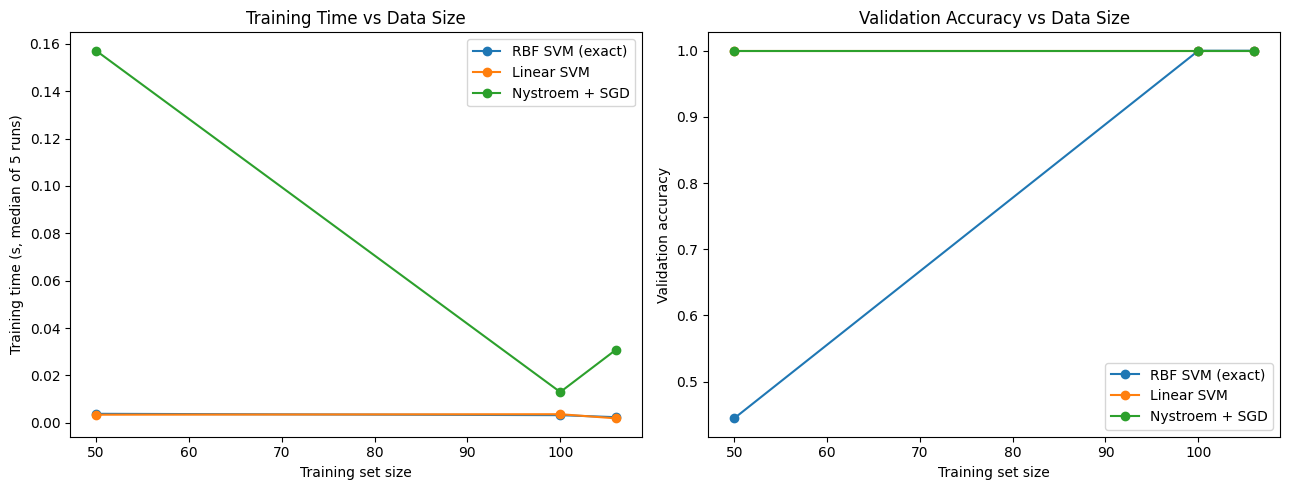

In [30]:
import time
from sklearn.svm import SVC, LinearSVC
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

train_sizes = [50, 100, 150, len(X_train)]
train_sizes = sorted(set(min(s, len(X_train)) for s in train_sizes))

rng = np.random.default_rng(42)
perm = rng.permutation(len(X_train))
X_train_shuf, y_train_shuf = X_train[perm], y_train[perm]

results = {"size": [], "model": [], "train_time": [], "val_acc": []}

best_gamma = best_gamma if 'best_gamma' in globals() else 0.1
best_C = best_C if 'best_C' in globals() else 1.0

def timed_fit(model_fn, X, y, n_repeats=5):
    times = []
    model = None
    for _ in range(n_repeats):
        t0 = time.perf_counter()
        model = model_fn()
        model.fit(X, y)
        times.append(time.perf_counter() - t0)
    return model, np.median(times)

for n in train_sizes:

    X_sub, y_sub = X_train_shuf[:n], y_train_shuf[:n]

    rbf_svm, t_rbf = timed_fit(lambda: SVC(kernel='rbf', C=best_C, gamma=best_gamma), X_sub, y_sub)
    acc_rbf = accuracy_score(y_val, rbf_svm.predict(X_val))

    lin_svm, t_lin = timed_fit(lambda: LinearSVC(C=best_C, max_iter=10000), X_sub, y_sub)
    acc_lin = accuracy_score(y_val, lin_svm.predict(X_val))

    approx_model, t_approx = timed_fit(
        lambda: make_pipeline(
            Nystroem(kernel='rbf', gamma=best_gamma, n_components=min(100, n)),
            SGDClassifier(loss='hinge', max_iter=2000, tol=1e-3)
        ),
        X_sub, y_sub
    )
    acc_approx = accuracy_score(y_val, approx_model.predict(X_val))

    for model_name, t, acc in [("RBF SVM (exact)", t_rbf, acc_rbf),
                                 ("Linear SVM", t_lin, acc_lin),
                                 ("Nystroem + SGD", t_approx, acc_approx)]:
        results["size"].append(n)
        results["model"].append(model_name)
        results["train_time"].append(t)
        results["val_acc"].append(acc)

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model_name in results_df["model"].unique():
    sub = results_df[results_df["model"] == model_name]
    axes[0].plot(sub["size"], sub["train_time"], marker='o', label=model_name)
    axes[1].plot(sub["size"], sub["val_acc"], marker='o', label=model_name)

axes[0].set_xlabel("Training set size")
axes[0].set_ylabel("Training time (s, median of 5 runs)")
axes[0].set_title("Training Time vs Data Size")
axes[0].legend()

axes[1].set_xlabel("Training set size")
axes[1].set_ylabel("Validation accuracy")
axes[1].set_title("Validation Accuracy vs Data Size")
axes[1].legend()

plt.tight_layout()
plt.show()

## 3.6 Bonus: Active sampling with Gaussian Process — 3 bonus pts

<div dir="rtl">

از فایل `diabetes_gp_pool.csv` استفاده کنید. نقطه‌ای را انتخاب کنید که Gaussian Process در آن بیشترین عدم قطعیت دارد، آن را به داده train اضافه کنید و مدل را دوباره fit کنید.

قبل و بعد از اضافه‌کردن نقطه، نمودار عدم قطعیت را مقایسه کنید.

سوال: چرا انتخاب نقطه با عدم قطعیت بالا می‌تواند در طراحی آزمایش یا active learning مفید باشد؟

</div>

In [18]:
# BONUS TODO: perform one active-sampling step based on predictive standard deviation